# Этап 4. Исследовательский анализ (EDA)

**Вход:** `data/processed/panel_regions_clean.csv` (20 регионов) и `panel_units_clean.csv` (16 сопоставимых единиц) — результат этапа 3.
**Вопрос этапа:** какие факторы связаны с доходами населения и что из этого следует для регрессии на этапе 6.

## Оглавление
1. [Настройка и загрузка](#setup)
2. [Обзор: разброс показателей в 2024 г.](#overview)
3. [Рейтинг регионов по доходу](#ranking)
4. [Карты: доход и продолжительность жизни](#maps)
5. [Форма распределений: что логарифмировать](#skew)
6. [Корреляции](#corr)
7. [Устойчивость связей во времени](#stability)
8. [Доход и продолжительность жизни (к H2)](#h2)
9. [Выводы и что это значит для регрессии](#summary)

**Почему корреляции считаем по одному году, а не по всей панели.** Все денежные показатели растут вместе с инфляцией, поэтому в объединённой панели 2015–2024 почти всё коррелирует со всем — это корреляция с годом, а не между регионами. Регионы сравниваем внутри года, а устойчивость связей проверяем, повторив расчёт для каждого года.

<a id="setup"></a>
## 1. Настройка и загрузка

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.collections import PatchCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch, Polygon
import matplotlib.patheffects as pe
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b4b2a9", "grid.color": "#e6e4dd",
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRAY, INK, MUTED = "#b4b2a9", "#0b0b0b", "#52514e"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#e8f1fb", "#9cc2ef", "#2a78d6", "#123e73"])
DIV = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f1ed", BLUE])

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

regions = pd.read_csv(DATA / "panel_regions_clean.csv")
units = pd.read_csv(DATA / "panel_units_clean.csv")
LAST = int(regions.year.max())
r = regions[regions.year == LAST].copy()

print(f"regions: {regions.shape}, units: {units.shape}; срез последнего года ({LAST}): {len(r)} регионов")

regions: (176, 27), units: (160, 25); срез последнего года (2024): 20 регионов


<a id="overview"></a>
## 2. Обзор: разброс показателей в 2024 г.

In [2]:
LABELS = {
    "income_pc": "Доход на душу, тенге/мес",
    "income_to_subsistence": "Доход / прожиточный минимум",
    "wage": "Зарплата, тенге",
    "grp_pc": "ВРП на душу, тенге",
    "investments_pc": "Инвестиции на душу, тенге",
    "housing_m2_per1000": "Ввод жилья, м² на 1000 чел.",
    "doctors_per10k": "Врачи на 10 тыс.",
    "unemployment": "Безработица, %",
    "informal_share": "Неформальная занятость, %",
    "poverty": "Бедность, %",
    "migration_per1000": "Сальдо миграции на 1000",
    "life_expectancy": "Продолжительность жизни, лет",
}
COLS = list(LABELS)

overview = pd.DataFrame({
    "медиана": r[COLS].median(),
    "мин.": r[COLS].min(),
    "макс.": r[COLS].max(),
    "макс./мин.": (r[COLS].max() / r[COLS].min()).where(r[COLS].min() > 0),
    "где минимум": [r.loc[r[c].idxmin(), "region"] for c in COLS],
    "где максимум": [r.loc[r[c].idxmax(), "region"] for c in COLS],
}).rename(index=LABELS)
overview.round(1)

,медиана,мин.,макс.,макс./мин.,где минимум,где максимум
"Доход на душу, тенге/мес",196889.0,121620.0,344454.0,2.8,Туркестанская,г. Алматы
Доход / прожиточный минимум,4.1,2.7,6.8,2.6,Туркестанская,Атырауская
"Зарплата, тенге",347673.0,293160.0,633322.0,2.2,Жетісу,Атырауская
"ВРП на душу, тенге",5685631.0,2175620.0,21177557.0,9.7,Туркестанская,Атырауская
"Инвестиции на душу, тенге",944635.0,436700.0,2911374.0,6.7,Жамбылская,Атырауская
"Ввод жилья, м² на 1000 чел.",689.4,482.6,2998.4,6.2,Карагандинская,г. Астана
Врачи на 10 тыс.,32.9,25.0,68.9,2.8,Алматинская,г. Астана
"Безработица, %",4.7,4.1,5.0,1.2,Карагандинская,Мангистауская
"Неформальная занятость, %",11.0,3.0,26.8,8.9,г. Шымкент,Западно-Казахстанская
"Бедность, %",4.5,2.7,8.5,3.1,г. Астана,Туркестанская


**Что видно:**
- **Доход на душу различается в 2,8 раза**: от 122 тыс. тенге в Туркестанской области до 344 тыс. в Алматы. ВРП на душу — в 9,7 раза (Атырауская против Туркестанской): богатство региона доходит до населения сильно сглаженным.
- **Безработица почти одинакова везде** (4,1–5,0%). У признака без разброса не может быть связи с доходом, поэтому в регрессии он бесполезен — как и ожидалось на этапе 1.
- **Продолжительность жизни** различается на 6 лет: от 72,5 в Ұлытау до 78,8 в Алматы.

<a id="ranking"></a>
## 3. Рейтинг регионов по доходу

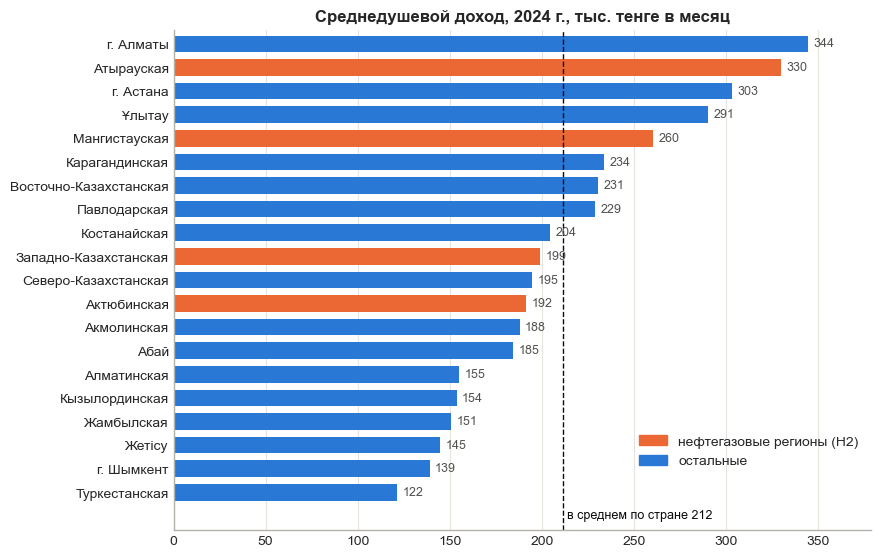

In [3]:
kz_income = regions.loc[regions.year == LAST, ["income_pc", "population"]]
kz_mean = np.average(kz_income.income_pc, weights=kz_income.population)

rank = r.sort_values("income_pc")
colors = [ORANGE if res else BLUE for res in rank.is_resource]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(rank.region, rank.income_pc / 1000, color=colors, height=0.7)
for y, (v, ratio) in enumerate(zip(rank.income_pc, rank.income_to_subsistence)):
    ax.text(v / 1000 + 3, y, f"{v / 1000:.0f}", va="center", fontsize=9, color=MUTED)
ax.axvline(kz_mean / 1000, color=INK, lw=1, ls="--")
ax.text(kz_mean / 1000 + 2, -1.1, f"в среднем по стране {kz_mean / 1000:.0f}", fontsize=9, color=INK)
ax.set_title(f"Среднедушевой доход, {LAST} г., тыс. тенге в месяц")
ax.set_xlim(0, rank.income_pc.max() / 1000 * 1.1)
ax.set_ylim(-1.6, len(rank) - 0.4)
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=["нефтегазовые регионы (H2)", "остальные"], frameon=False,
          loc="lower right", bbox_to_anchor=(1, 0.1))
fig.savefig(IMAGES / "01_income_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод:** в верхней пятёрке — два мегаполиса (Алматы, Астана), нефтяная Атырауская область и горнодобывающая Ұлытау. Внизу — юг: Туркестанская, Шымкент, Жетісу, Жамбылская. Выше среднего по стране (212 тыс.) — только 8 регионов из 20: среднее тянут вверх два мегаполиса, где живёт почти пятая часть населения (18%).

Обратите внимание на **Ұлытау**: доход 291 тыс., четвёртое место, хотя в группу «сырьевых» для H2 она не входит — мы отнесли туда только нефтегазовые области. Её экономика держится на добыче меди (Жезказган). На этапе 7 проверим, меняется ли вывод H2, если расширить группу горнодобывающими регионами.

<a id="maps"></a>
## 4. Карты: доход и продолжительность жизни

Границы — GeoJSON из этапа 2 (HDX, версия 2023 г. с областями Абай, Жетісу, Ұлытау). Регионы связываются по полю `ADM1_EN` = `name_en`.

Регионов на карте: 20, без границ: нет


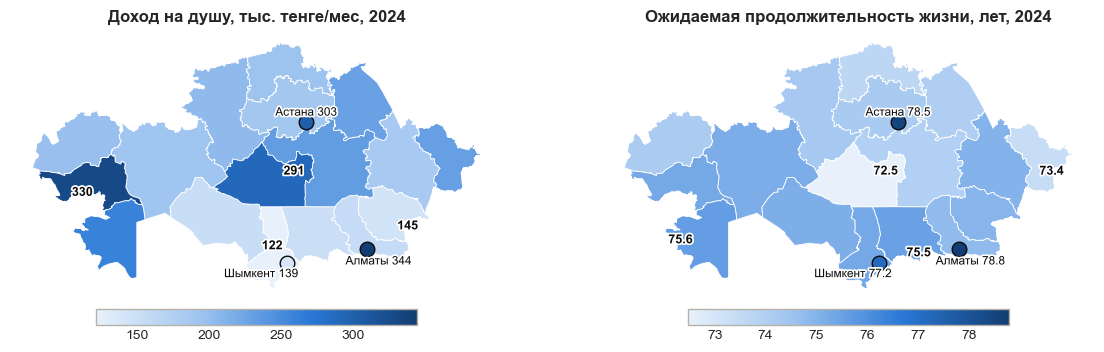

In [4]:
geo = json.loads((ROOT / "data" / "raw" / "kz_regions.geojson").read_text(encoding="utf-8"))

def rings(geometry):
    if geometry["type"] == "Polygon":
        return [geometry["coordinates"][0]]
    return [poly[0] for poly in geometry["coordinates"]]

SHAPES = {f["properties"]["ADM1_EN"]: rings(f["geometry"]) for f in geo["features"]}
missing = set(r.name_en) - set(SHAPES)
print(f"Регионов на карте: {len(SHAPES)}, без границ: {missing or 'нет'}")

CITIES = {"Astana": "Астана", "Almaty": "Алматы", "Shymkent": "Шымкент"}
CITY_OFFSET = {"Astana": (0, 9e4), "Almaty": (1.2e5, -1.3e5), "Shymkent": (-2.6e5, -1.1e5)}
LABEL_SHIFT = {"Turkistan Region": (-1.0e5, 2.4e5)}   # чтобы подпись не закрывал кружок Шымкента
HALO = [pe.withStroke(linewidth=2.5, foreground="white")]

def centroid(name):
    return np.array(max(SHAPES[name], key=len)).mean(axis=0)

def draw_map(ax, values: pd.Series, title: str, fmt: str, label_top: int = 2):
    norm = Normalize(values.min(), values.max())
    patches, colors = [], []
    for name, ring_list in SHAPES.items():
        for ring in ring_list:
            patches.append(Polygon(np.array(ring), closed=True))
            colors.append(SEQ(norm(values[name])))
    ax.add_collection(PatchCollection(patches, facecolor=colors, edgecolor="white", linewidth=0.6))
    # города слишком малы на карте — показываем кружками
    for name, label in CITIES.items():
        x, y = centroid(name)
        ax.scatter(x, y, s=110, color=SEQ(norm(values[name])), edgecolor=INK, linewidth=1, zorder=4)
        dx, dy = CITY_OFFSET[name]
        ax.text(x + dx, y + dy, f"{label} {fmt.format(values[name])}", fontsize=8.5, color=INK,
                ha="center", va="center", path_effects=HALO, zorder=5)
    # подписи областей с крайними значениями
    oblasts = values.drop(list(CITIES))
    for name in list(oblasts.nlargest(label_top).index) + list(oblasts.nsmallest(label_top).index):
        x, y = centroid(name) + np.array(LABEL_SHIFT.get(name, (0, 0)))
        ax.text(x, y, fmt.format(values[name]), ha="center", va="center", fontsize=9,
                color=INK, fontweight="bold", path_effects=HALO)
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
    sm = plt.cm.ScalarMappable(cmap=SEQ, norm=norm)
    plt.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.04, pad=0.02, shrink=0.7)

by_name = r.set_index("name_en")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
draw_map(axes[0], by_name.income_pc / 1000, f"Доход на душу, тыс. тенге/мес, {LAST}", "{:.0f}")
draw_map(axes[1], by_name.life_expectancy, f"Ожидаемая продолжительность жизни, лет, {LAST}", "{:.1f}")
fig.savefig(IMAGES / "02_maps_income_life.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод:** карты почти не похожи друг на друга. Доход концентрируется на западе (нефть), в центре (горнодобыча) и в двух мегаполисах. Продолжительность жизни выше на юге и в городах, а самая низкая — в центре, на востоке и севере: Ұлытау (72,5), ВКО (73,4), Северо-Казахстанская (73,7), Карагандинская и Павлодарская (74,0–74,1). Центр — богатый, но с самой короткой жизнью; юг — бедный, но живёт дольше. Это первый аргумент в пользу H2: деньги региона не превращаются автоматически в здоровье. Города республиканского значения показаны кружками (на карте их территория слишком мала), у областей подписаны по два крайних значения.

<a id="skew"></a>
## 5. Форма распределений: что логарифмировать

Линейная регрессия (этап 6) чувствительна к длинным хвостам: один регион с огромными инвестициями будет «тянуть» линию на себя. Смотрим асимметрию (skewness) на сопоставимой панели: |skew| > 1 — сильная.

In [5]:
SKEW_COLS = ["income_pc", "wage", "grp_pc", "investments_pc", "housing_m2_per1000", "doctors_per10k", "informal_share"]
skew = pd.DataFrame({
    "асимметрия": units[SKEW_COLS].skew(),
    "асимметрия log": np.log(units[SKEW_COLS]).skew(),
}).rename(index=LABELS).round(2)
skew["решение"] = np.where(skew["асимметрия"].abs() > 1, "логарифм", "как есть")
skew

,асимметрия,асимметрия log,решение
"Доход на душу, тенге/мес",1.10,0.06,логарифм
"Зарплата, тенге",1.15,0.16,логарифм
"ВРП на душу, тенге",2.43,0.22,логарифм
"Инвестиции на душу, тенге",3.77,0.98,логарифм
"Ввод жилья, м² на 1000 чел.",1.77,0.17,логарифм
Врачи на 10 тыс.,1.66,1.04,логарифм
"Неформальная занятость, %",0.44,-0.80,как есть


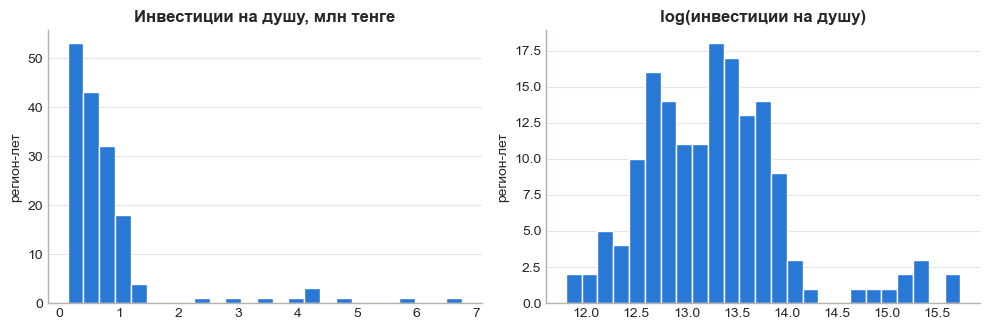

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(units.investments_pc / 1e6, bins=25, color=BLUE, edgecolor="white")
axes[0].set_title("Инвестиции на душу, млн тенге")
axes[1].hist(np.log(units.investments_pc), bins=25, color=BLUE, edgecolor="white")
axes[1].set_title("log(инвестиции на душу)")
for ax in axes:
    ax.set_ylabel("регион-лет")
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Вывод:** инвестиции, ВРП, ввод жилья и врачи на душу — с длинным правым хвостом (асимметрия 1,7–3,8); после логарифма она падает до 0,2–1,0. Асимметрия дохода и зарплаты (≈ 1,1) отчасти создана ростом цен за 10 лет, но их тоже логарифмируем: модель «логарифм на логарифм» даёт понятные коэффициенты — на сколько процентов меняется доход при росте фактора на 1%. Неформальную занятость оставляем как есть: после логарифма асимметрия становится хуже (−0,8). Сальдо миграции логарифмировать нельзя — оно бывает отрицательным.

<a id="corr"></a>
## 6. Корреляции

Используем корреляцию **Спирмена**: она работает с рангами, не боится выбросов (Астана, Атырау) и не требует нормальности. При 20 регионах значимой на уровне 5% будет связь примерно от |ρ| ≥ 0,45.

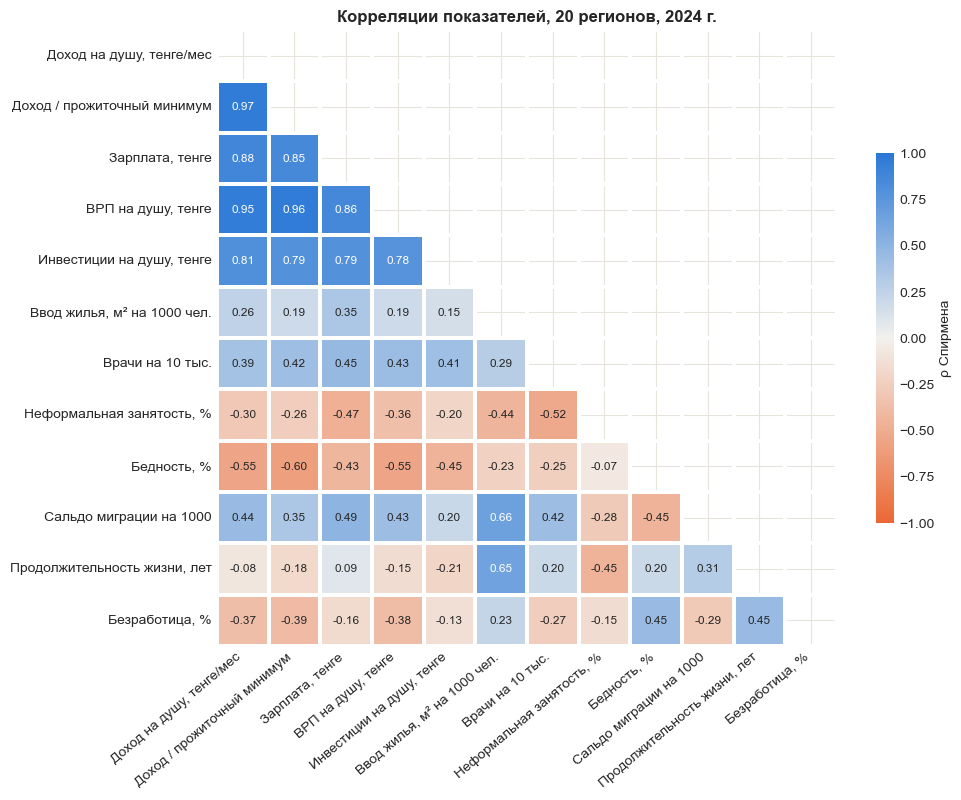

In [7]:
CORR_COLS = [c for c in COLS if c != "unemployment"] + ["unemployment"]
rho = r[CORR_COLS].corr(method="spearman")

mask = np.triu(np.ones_like(rho, dtype=bool))
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(rho, mask=mask, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8.5}, linewidths=1.5, linecolor="white",
            xticklabels=[LABELS[c] for c in CORR_COLS], yticklabels=[LABELS[c] for c in CORR_COLS],
            cbar_kws={"shrink": 0.6, "label": "ρ Спирмена"}, ax=ax)
ax.set_title(f"Корреляции показателей, 20 регионов, {LAST} г.")
plt.xticks(rotation=40, ha="right")
fig.savefig(IMAGES / "03_corr_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
rows = []
for c in CORR_COLS[1:]:
    rho_c, p = stats.spearmanr(r.income_pc, r[c])
    rows.append({"фактор": LABELS[c], "ρ с доходом": round(rho_c, 2), "p-value": round(p, 4),
                 "значима (p < 0,05)": "да" if p < 0.05 else "нет"})
pd.DataFrame(rows).sort_values("ρ с доходом", key=abs, ascending=False).reset_index(drop=True)

,фактор,ρ с доходом,p-value,"значима (p < 0,05)"
0,Доход / прожиточный минимум,0.97,0.0000,да
1,"ВРП на душу, тенге",0.95,0.0000,да
2,"Зарплата, тенге",0.88,0.0000,да
3,"Инвестиции на душу, тенге",0.81,0.0000,да
4,"Бедность, %",-0.55,0.0125,да
5,Сальдо миграции на 1000,0.44,0.0537,нет
6,Врачи на 10 тыс.,0.39,0.0910,нет
7,"Безработица, %",-0.37,0.1074,нет
8,"Неформальная занятость, %",-0.30,0.1952,нет
9,"Ввод жилья, м² на 1000 чел.",0.26,0.2767,нет


**Выводы по корреляциям:**
1. **Доход сильнее всего связан с «размером экономики»**: ВРП на душу (ρ = 0,95), зарплата (0,88), инвестиции (0,81). Но эти три показателя связаны и между собой (0,78–0,86) — это почти один и тот же признак. В регрессии их нельзя ставить вместе: будет мультиколлинеарность, коэффициенты станут неустойчивыми. Выбираем один «экономический» фактор.
2. **Связь с медициной слабая**: врачи на 10 тыс. — ρ = 0,39, статистически незначима при 20 регионах. Это предварительный аргумент **в пользу H1**: доходы сильнее связаны с экономикой и занятостью, чем с медициной.
3. **Бедность** закономерно ниже там, где выше доход (ρ = −0,55).
4. **Продолжительность жизни с доходом не связана** (ρ = −0,08), зато связана с численностью населения (0,64) и вводом жилья (0,65). Это растущие молодые регионы — юг и мегаполисы.
5. **Безработица** почти не меняется между регионами, поэтому и связей у неё нет — исключаем из модели.
6. **Неформальная занятость** на 20 регионах в 2024 г. связана с доходом слабо (−0,30, незначимо), а на 16 сопоставимых единицах — заметно (−0,55, раздел 7). Разница из-за Шымкента: он бедный, но с самой низкой неформальной занятостью в стране (3%), а в сопоставимых границах объединён с Туркестанской областью (17,8%). Небольшая выборка чувствительна к одной точке — поэтому важно проверять устойчивость.

<a id="stability"></a>
## 7. Устойчивость связей во времени

Один год — это 20 точек, случайность может исказить картину. Повторяем расчёт корреляции с доходом для каждого года 2015–2024 на 16 сопоставимых единицах.

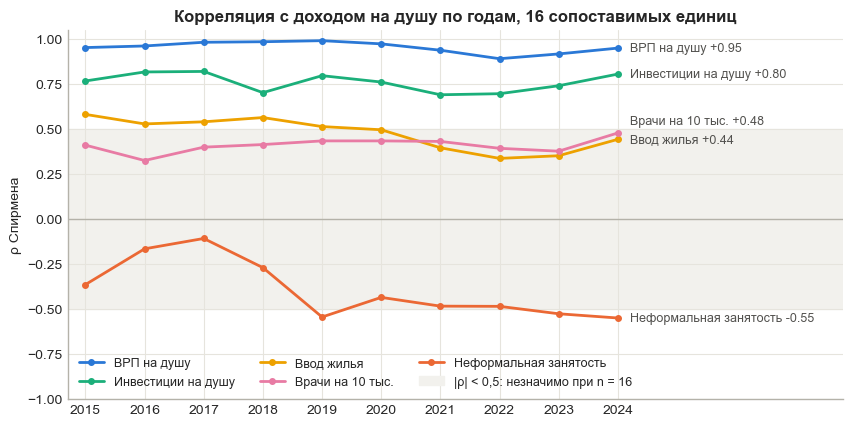

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
ВРП на душу,0.95,0.96,0.98,0.98,0.99,0.97,0.94,0.89,0.91,0.95
Инвестиции на душу,0.76,0.81,0.82,0.70,0.79,0.76,0.69,0.69,0.74,0.80
Ввод жилья,0.58,0.53,0.54,0.56,0.51,0.49,0.39,0.34,0.35,0.44
Врачи на 10 тыс.,0.41,0.32,0.40,0.41,0.43,0.43,0.43,0.39,0.38,0.48
Неформальная занятость,-0.36,-0.17,-0.11,-0.27,-0.54,-0.44,-0.48,-0.49,-0.53,-0.55


In [9]:
FACTORS = {
    "grp_pc": ("ВРП на душу", BLUE),
    "investments_pc": ("Инвестиции на душу", AQUA),
    "housing_m2_per1000": ("Ввод жилья", YELLOW),
    "doctors_per10k": ("Врачи на 10 тыс.", MAGENTA),
    "informal_share": ("Неформальная занятость", ORANGE),
}
stab = pd.DataFrame({
    label: {year: stats.spearmanr(g.income_pc, g[c])[0] for year, g in units.groupby("year")}
    for c, (label, _) in FACTORS.items()
})

fig, ax = plt.subplots(figsize=(10, 4.8))
for c, (label, color) in FACTORS.items():
    ax.plot(stab.index, stab[label], color=color, lw=2, marker="o", ms=4, label=label)

# подписи справа, раздвинутые, чтобы не налезали друг на друга
ends = stab.iloc[-1].sort_values()
ypos, prev = {}, -np.inf
for label, y in ends.items():
    ypos[label] = max(y, prev + 0.1)
    prev = ypos[label]
for label, y in ypos.items():
    ax.text(stab.index[-1] + 0.2, y, f"{label} {ends[label]:+.2f}", va="center", fontsize=9, color=MUTED)

ax.axhline(0, color=GRAY, lw=1)
ax.axhspan(-0.5, 0.5, color="#f2f1ed", zorder=0)
ax.set_ylim(-1, 1.05)
ax.set_xlim(2014.7, 2027.8)
ax.set_xticks(stab.index)
ax.set_title("Корреляция с доходом на душу по годам, 16 сопоставимых единиц")
ax.set_ylabel("ρ Спирмена")
handles, labels_ = ax.get_legend_handles_labels()
handles.append(Patch(color="#f2f1ed"))
labels_.append("|ρ| < 0,5: незначимо при n = 16")
ax.legend(handles, labels_, frameon=False, ncol=3, loc="lower left", fontsize=9)
fig.savefig(IMAGES / "04_corr_stability.png", dpi=150, bbox_inches="tight")
plt.show()

stab.round(2).T

**Вывод:**
- **ВРП и инвестиции** связаны с доходом стабильно сильно все 10 лет (ρ 0,89–0,99 и 0,69–0,82) — это не случайность одного года.
- **Неформальная занятость** — самое интересное: связь с доходом **усиливается** — от −0,11…−0,36 в 2015–2018 гг. до −0,44…−0,55 с 2019 г. Регионы с большой «теневой» занятостью всё сильнее отстают по доходам. Это аргумент в пользу программ легализации занятости как инструмента для отстающих регионов.
- **Ввод жилья** со временем теряет связь с доходом: 0,5–0,6 в 2015–2020 гг. и 0,34–0,44 после. Строят всё больше там, где растёт население, а не там, где богаче.
- **Врачи** всё время держатся в зоне слабых связей (0,32–0,48).

<a id="h2"></a>
## 8. Доход и продолжительность жизни (к H2)

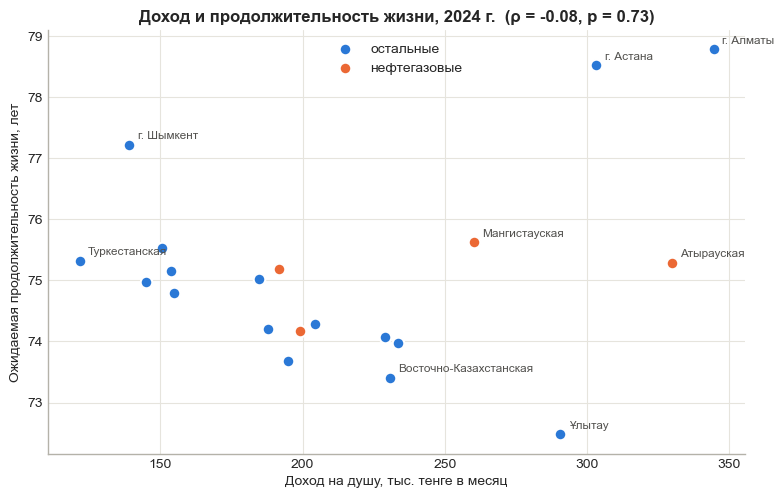

Медианы: нефтегазовые — доход 230 тыс., жизнь 75.2 лет; остальные — доход 191 тыс., жизнь 74.9 лет


In [10]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for res, color, label in [(False, BLUE, "остальные"), (True, ORANGE, "нефтегазовые")]:
    d = r[r.is_resource == res]
    ax.scatter(d.income_pc / 1000, d.life_expectancy, s=70, color=color, edgecolor="white", linewidth=1.5, label=label, zorder=3)

NOTE = ["Ұлытау", "Туркестанская", "г. Алматы", "г. Астана", "Атырауская", "Восточно-Казахстанская", "г. Шымкент", "Мангистауская"]
for _, row in r[r.region.isin(NOTE)].iterrows():
    ax.annotate(row.region, (row.income_pc / 1000, row.life_expectancy), xytext=(6, 4),
                textcoords="offset points", fontsize=8.5, color=MUTED)

rho_le, p_le = stats.spearmanr(r.income_pc, r.life_expectancy)
ax.set_title(f"Доход и продолжительность жизни, {LAST} г.  (ρ = {rho_le:.2f}, p = {p_le:.2f})")
ax.set_xlabel("Доход на душу, тыс. тенге в месяц")
ax.set_ylabel("Ожидаемая продолжительность жизни, лет")
ax.legend(frameon=False, loc="upper center")
fig.savefig(IMAGES / "05_income_vs_life.png", dpi=150, bbox_inches="tight")
plt.show()

g = r.groupby("is_resource")[["income_pc", "life_expectancy"]].median()
print(f"Медианы: нефтегазовые — доход {g.loc[True, 'income_pc'] / 1000:.0f} тыс., жизнь {g.loc[True, 'life_expectancy']:.1f} лет; "
      f"остальные — доход {g.loc[False, 'income_pc'] / 1000:.0f} тыс., жизнь {g.loc[False, 'life_expectancy']:.1f} лет")

**Вывод:** облако точек без наклона. У Ұлытау доход почти 290 тыс. и самая короткая жизнь в стране (72,5 года), у Туркестанской — доход вдвое ниже, а живут почти на 3 года дольше. Хорошо живут только мегаполисы, где одновременно высокие доходы и самая плотная сеть медицины (Алматы и Астана — 64 и 69 врачей на 10 тыс. против медианы 33). Нефтегазовые регионы богаче остальных, но по продолжительности жизни от них не отличаются. Статистически H2 проверим на этапе 7.

<a id="summary"></a>
## 9. Выводы и что это значит для регрессии

**Главное:**
1. **Доход в 2,8 раза выше в лучшем регионе, чем в худшем**, и определяется в первую очередь экономикой региона: ВРП, зарплатами, инвестициями (ρ 0,81–0,95, устойчиво все 10 лет).
2. **Медицина с доходом связана слабо** (ρ ≈ 0,4, незначимо) — предварительно H1 подтверждается.
3. **Неформальная занятость — растущий фактор отставания**: её связь с доходом за 10 лет усилилась с −0,1…−0,4 до −0,55.
4. **Богатство региона не превращается в продолжительность жизни** (ρ = −0,08): центр богат, но живёт меньше всех, юг беден, но живёт дольше — предварительно H2 подтверждается.

**Решения для этапа 6 (регрессия):**
| Решение | Почему |
|---|---|
| Модель строим на 16 сопоставимых единицах, 2015–2024 | в границах своего года реформы дают ложные скачки |
| ВРП, инвестиции и зарплату в модель одновременно не ставим | ρ между ними 0,78–0,86 — мультиколлинеарность |
| Доход и денежные факторы, врачей и ввод жилья логарифмируем | асимметрия 1,1–3,8; коэффициенты читаются как эластичности |
| Безработицу исключаем | не различается между регионами (4,1–5,0%) |
| Добавляем фиктивные переменные лет | убрать общий рост цен, оставить различия между регионами |
| Флаг `covid` учитываем в моделях продолжительности жизни | провал 2020–2021 гг. |